# Experimento 01 - Análise Temática de Diálogos

##### Durante essse experimeto serão utilizados arquivos pdf que contém diálogos gerados pelo Chat GPT 5. 

In [27]:
#pip install -r requirements.txt

### Importando as bibliotecas necessárias

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

from langchain_openai import AzureOpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

from PyPDF2 import PdfReader, PdfWriter

from dotenv import load_dotenv
import os


### 1 - Diálogo entre duas pessoas 

##### Nessa etapa foi utilizado um diálogo continuo sobre finanças entre duas pessoas. 

#### 1.1 - Carregamento e Extração de Texto com PyPDFLoader

In [29]:
file_path_dialogo1 = "pdfs/dialogo_financas.pdf"
loader_dialogo1 = PyPDFLoader(file_path_dialogo1)
pages_dialogo1 = loader_dialogo1.load()

print(f"{len(pages_dialogo1)} páginas")

2 páginas


#### 1.2 - Divisão do Texto em chunks com RecursiveCharacterTextSplitter

In [30]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=10,        
    chunk_overlap=2       
)

chunks_dialogo1 = text_splitter.split_documents(pages_dialogo1)
print(f"{len(chunks_dialogo1)} chunks")

679 chunks


#### 1.3 - Geração de Embeddings com AzureOpenAIEmbeddings

In [31]:
load_dotenv()

embeddings = AzureOpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

vetor_dialogo1 = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_dialogo1]))

#### 1.4 -  Redução de Dimensionalidade com t-SNE

In [32]:
tsne1 = TSNE(n_components=2, random_state=42, perplexity=2)
vectors_tsne1 = tsne1.fit_transform(vetor_dialogo1)

#### 1.5 - Gráfico

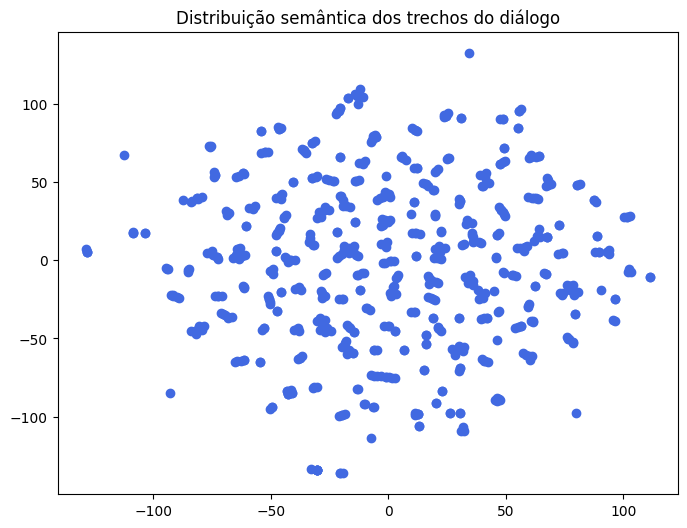

In [33]:
plt.figure(figsize=(8,6))
plt.scatter(vectors_tsne1[:,0], vectors_tsne1[:,1], color="royalblue")
plt.title("Distribuição semântica dos trechos do diálogo")
plt.show()

### 2 - Três pessoas conversando sobre assuntos completamente diferentes

##### O processo do item 1 foi repetido aqui, com a adição da formsção de clusters . O diálogo utilizado é completamente desconexo, são três pessoas falando de assuntos completamente diferentes, como se elas estivessem ignorando umas as outras.

In [34]:
file_path_dialogo2 = "pdfs/dialogo_tres_pessoas_sem_conexao.pdf"
loader_dialogo2 = PyPDFLoader(file_path_dialogo2)
pages_dialogo2 = loader_dialogo2.load()
print(f"{len(pages_dialogo2)} páginas")

text_splitter2 = RecursiveCharacterTextSplitter(
    separators=["\n\n", "\n", ".", " "],
    chunk_size=400,
    chunk_overlap=50,
    length_function=len,
    is_separator_regex=False,
)
chunks_dialogo2 = text_splitter2.split_documents(pages_dialogo2)
print(f"{len(chunks_dialogo2)} chunks")

vector_dialogo2 = np.array(
    embeddings.embed_documents([chunk.page_content for chunk in chunks_dialogo2])
)

tsne2 = TSNE(n_components=2, random_state=42, perplexity=10)
vectors_tsne2 = tsne2.fit_transform(vector_dialogo2)

num_clusters3 = 3
kmeans3 = KMeans(n_clusters=num_clusters3, random_state=42)
clusters3 = kmeans3.fit_predict(vector_dialogo2)


6 páginas
41 chunks


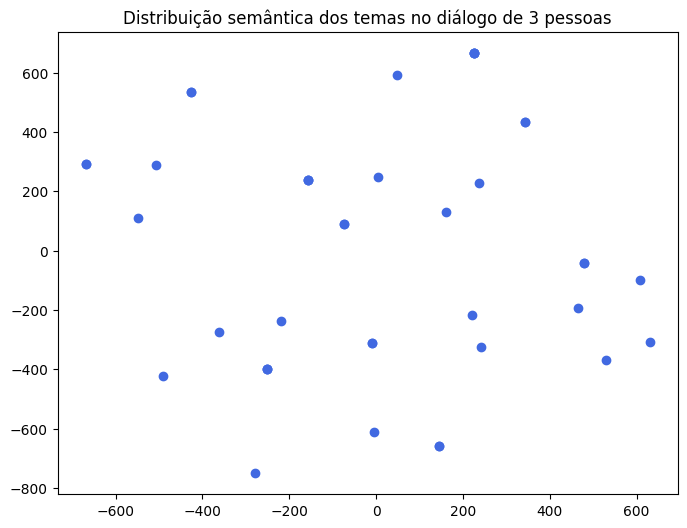

In [35]:
plt.figure(figsize=(8,6))
plt.scatter(vectors_tsne2[:,0], vectors_tsne2[:,1], color="royalblue")
plt.title("Distribuição semântica dos temas no diálogo de 3 pessoas")
plt.show()

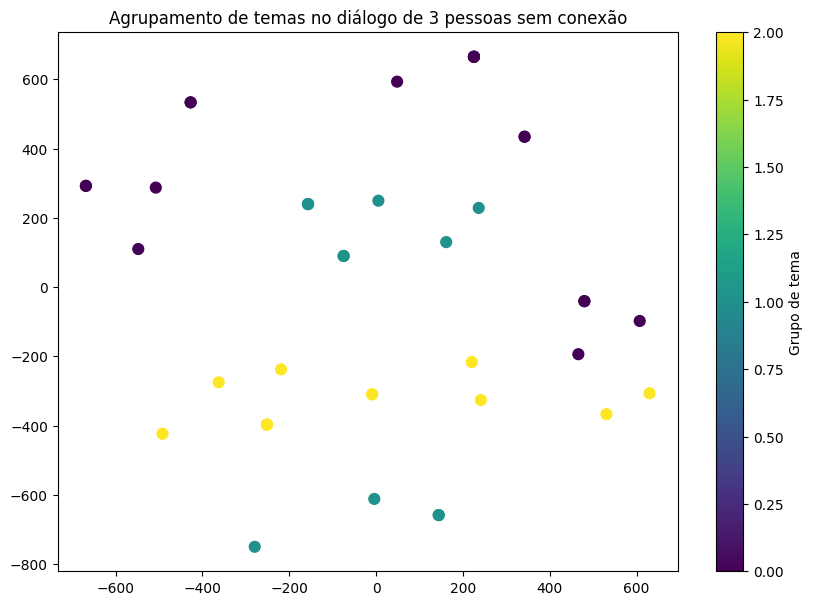

In [36]:
plt.figure(figsize=(10,7))
plt.scatter(vectors_tsne2[:,0], vectors_tsne2[:,1], c=clusters3, cmap="viridis", s=60)
plt.title("Agrupamento de temas no diálogo de 3 pessoas sem conexão")
plt.colorbar(label="Grupo de tema")
plt.show()

### 3 - Duas pessoas conversando e uma intrusa

##### O processo do item 1 foi repetido aqui, com a adição da formação de clusters . O diálogo utilizado tem duas pessoas em uma conversa contínua e uma pessoa completamente desconexa, como se ela estivesse sendo ignorada

In [37]:
file_path_dialogo3 = "pdfs/dialogo_duplo_com_intrusa.pdf"
loader_dialogo3 = PyPDFLoader(file_path_dialogo3)
pages_dialogo3 = loader_dialogo3.load()
print(f"{len(pages_dialogo3)} páginas")

text_splitter3 = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=700,
    length_function=len,
    is_separator_regex=False,
)
chunks_dialogo3 = text_splitter3.split_documents(pages_dialogo3)
print(f"{len(chunks_dialogo3)} chunks")

vector_dialogo3 = np.array(
    embeddings.embed_documents([chunk.page_content for chunk in chunks_dialogo3])
)

tsne3 = TSNE(n_components=2, random_state=42, perplexity=10)
vectors_tsne3 = tsne3.fit_transform(vector_dialogo3)

num_clusters3 = 3
kmeans3 = KMeans(n_clusters=num_clusters3, random_state=42)
clusters3 = kmeans3.fit_predict(vector_dialogo3)


6 páginas
31 chunks


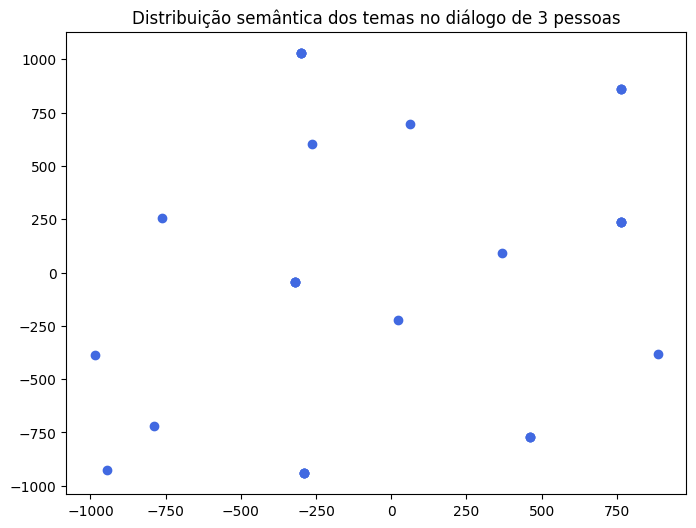

In [38]:
plt.figure(figsize=(8,6))
plt.scatter(vectors_tsne3[:,0], vectors_tsne3[:,1], color="royalblue")
plt.title("Distribuição semântica dos temas no diálogo de 3 pessoas")
plt.show()

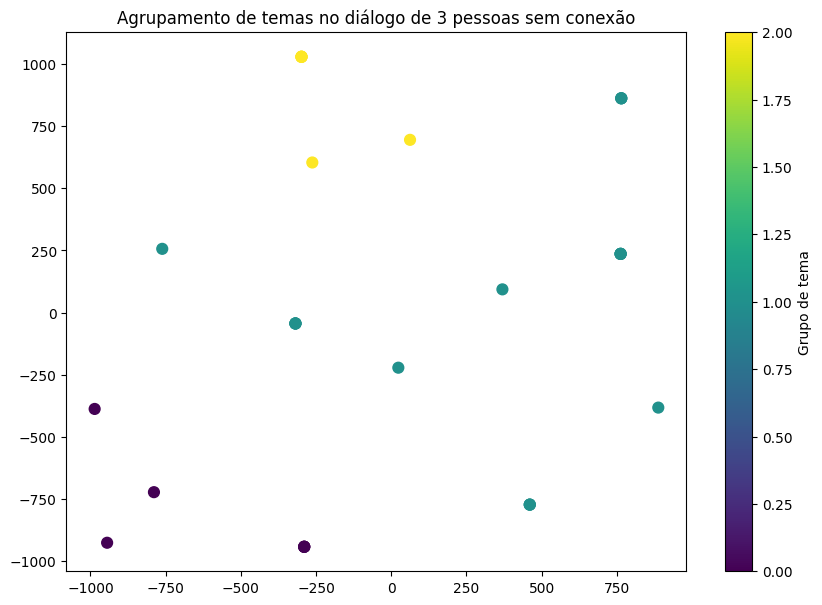

In [39]:
plt.figure(figsize=(10,7))
plt.scatter(vectors_tsne3[:,0], vectors_tsne3[:,1], c=clusters3, cmap="viridis", s=60)
plt.title("Agrupamento de temas no diálogo de 3 pessoas sem conexão")
plt.colorbar(label="Grupo de tema")
plt.show()

### 4 - Testando um ambiente muito controlado

##### Nessa etapa foram utilizados PDFs de livros didáticos, considerados ambientes muito controlados, já que os contextos não mudam, a similaridade semântica é muito alta. O processo é bem similar ao dos itens anteriores, a alteração mais significativas foi o processamentos dos PDFs, que foi utilizado o PyPDF2 para a seleção de páginas.

In [57]:
file_path_bio = "pdfs/Biologia_I.pdf"  
temp_bio_path = "pdfs/Biologia_I_pag_65_90.pdf"

reader = PdfReader(file_path_bio)
writer = PdfWriter()

for i in range(64, 90):  
    writer.add_page(reader.pages[i])

with open(temp_bio_path, "wb") as f:
    writer.write(f)

loader_dialogo_bio = PyPDFLoader(temp_bio_path)
pages_dialogo_bio = loader_dialogo_bio.load()
print(f"Biologia: {len(pages_dialogo_bio)} páginas carregadas")


file_path_mat = "pdfs/Matematica_I.pdf"  
temp_mat_path = "pdfs/Matematica_I_pag_65_90.pdf"

reader2 = PdfReader(file_path_mat)
writer2 = PdfWriter()

for i in range(64, 90):
    writer2.add_page(reader2.pages[i])

with open(temp_mat_path, "wb") as f:
    writer2.write(f)

loader_dialogo_mat = PyPDFLoader(temp_mat_path)
pages_dialogo_mat = loader_dialogo_mat.load()
print(f"Matemática: {len(pages_dialogo_mat)} páginas carregadas")


Biologia: 26 páginas carregadas
Matemática: 26 páginas carregadas


In [58]:
text_splitter_livros = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100,
)

chunks_bio = text_splitter_livros.split_documents(pages_dialogo_bio)
chunks_mat = text_splitter_livros.split_documents(pages_dialogo_mat)

print(f"Biologia: {len(chunks_bio)} chunks")
print(f"Matemática: {len(chunks_mat)} chunks")

Biologia: 128 chunks
Matemática: 106 chunks


In [ ]:
vectors_mat = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_mat]))
vectors_bio = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_bio]))

all_vectors = np.concatenate([vectors_mat, vectors_bio], axis=0)

In [60]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

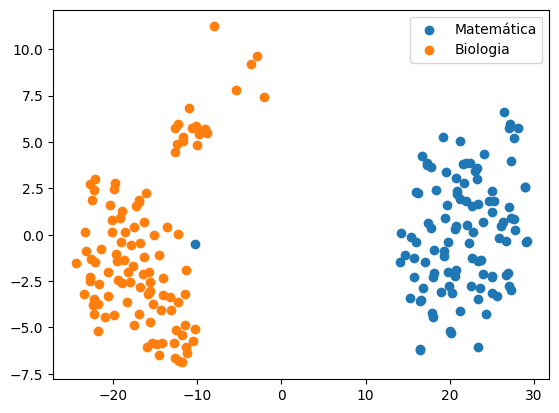

In [61]:
plt.scatter(all_vectors_tsne[:len(vectors_mat), 0], all_vectors_tsne[:len(vectors_mat), 1], label="Matemática")
plt.scatter(all_vectors_tsne[len(vectors_bio):, 0], all_vectors_tsne[len(vectors_bio):, 1], label="Biologia")
plt.legend()
plt.show()